# Análise de Vendas para Loja de E-commerce
### com NumPy, Pandas, Matplotlib e Seaborn

## Definição do Problema de Negócio

**O problema de negócio**

Nossa loja de e-commerce está em fase de crescimento, com um volume crescente de transações diárias.

Mas muitas de nossas decisões estratégicas são baseadas em intuição e observações parciais, com os seguintes desafios:

- **Gestão de estoque ineficiente:** não temos clareza sobre quais produtos são nossos "campeões de venda".
- **Marketing com baixo retorno:** nossas campanhas de marketing são genéricas.
- **Perda de oportunidades sazonais:** não conseguimos identificar padrões ou tendências de vendas ao longo dos meses.
- **Expansão sem direção:** para onde investir?

O problema central é a falta de visibilidade sobre a performance do negócio.

**Objetivos do projeto**

Este projeto de análise de dados visa transformar nossos dados brutos de vendas em insights acionáveis, respondendo a quatro perguntas de negócio:

- O que vender?
- Onde focar?
- Quando agir?
- Para onde expandir?

**Solução proposta**

Consolidar, limpar e analisar o histórico de vendas da plataforma com Python (Pandas, NumPy e Matplotlib), e criar um relatório visual que apresente as descobertas de forma clara para as equipes de gestão, marketing e operações.

**Resultados esperados**

- Otimização de estoque
- Marketing direcionado e eficaz
- Planejamento estratégico
- Decisões baseadas em dados, e não em intuição

> Os dados usados aqui são **fictícios**, gerados pela própria função do notebook.

## Importação das Bibliotecas

In [1]:
# Manipulação de dados em tabelas
import pandas as pd

# Operações matemáticas e arrays
import numpy as np

# Geração de gráficos
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Visualização estatística de dados
import seaborn as sns

# Geração de números aleatórios
import random

# Manipulação de datas e intervalos de tempo
from datetime import datetime, timedelta

# Pasta onde os gráficos serão salvos
import os
os.makedirs('imagens', exist_ok=True)

# Semente fixa: os dados aleatórios saem iguais a cada execução
random.seed(42)
np.random.seed(42)

# Função que formata eixos em milhares: 'R$ 250K'
def formatador_milhares(y, pos):
    """Formata o valor em milhares (K) com cifrão R$."""
    return f'R$ {y/1000:,.0f}K'

# Exibe os gráficos dentro do notebook
%matplotlib inline

## Função para Geração de Dados Fictícios

Aplicação prática de vários conceitos de Python puro e de Data Science: dicionários, listas, laços, condicionais, funções e DataFrames.

In [2]:
def gera_dados_ficticios(num_registros=600):
    """
    Gera um DataFrame do Pandas com dados de vendas fictícios.
    """

    # Mensagem inicial indicando a quantidade de registros a serem gerados
    print(f'\n Iniciando a geração de {num_registros} registros de vendas...')

    # Dicionário com produtos, suas categorias e preços
    produtos = {
        'Laptop Gamer': {'categoria': 'Eletrônicos', 'preco': 7500.00},
        'Mouse Vertical': {'categoria': 'Eletrônicos', 'preco': 250.00},
        'Teclado Mecânico': {'categoria': 'Acessórios', 'preco': 550.00},
        'Monitor Ultrawide': {'categoria': 'Acessórios', 'preco': 2800.00},
        'Cadeira Gamer': {'categoria': 'Móveis', 'preco': 7500.00},
        'Headset 7.1': {'categoria': 'Acessórios', 'preco': 800.00},
        'Placa de Vídeo': {'categoria': 'Hardware', 'preco': 4500.00},
        'SSD 1TB': {'categoria': 'Hardware', 'preco': 600.00}
    }

    # Lista apenas com os nomes dos produtos
    lista_produtos = list(produtos.keys())

    # Dicionário com cidades e seus respectivos estados
    cidades_estados = {
        'São Paulo': 'SP', 'Rio de Janeiro': 'RJ', 'Belo Horizonte': 'MG',
        'Porto Alegre': 'RS', 'Salvador': 'BA', 'Curitiba': 'PR', 'Fortaleza': 'CE'
    }

    # Lista apenas com os nomes das cidades
    lista_cidades = list(cidades_estados.keys())

    # Lista que armazenará os registros de vendas
    dados_vendas = []

    # Data inicial dos pedidos
    data_inicial = datetime(2026, 1, 1)

    # Loop para gerar os registros de vendas
    for i in range(num_registros):

        # Seleciona aleatoriamente um produto e uma cidade
        produto_nome = random.choice(lista_produtos)
        cidade = random.choice(lista_cidades)

        # Quantidade vendida entre 1 e 7
        quantidade = np.random.randint(1, 8)

        # Data do pedido: 5 pedidos por dia, em horários aleatórios
        data_pedido = data_inicial + timedelta(days=int(i / 5), hours=random.randint(0, 23))

        # Mouse e Teclado recebem desconto aleatório de até 10%
        if produto_nome in ['Mouse Vertical', 'Teclado Mecânico']:
            preco_unitario = produtos[produto_nome]['preco'] * np.random.uniform(0.9, 1.0)
        else:
            preco_unitario = produtos[produto_nome]['preco']

        # Adiciona um registro de venda à lista
        dados_vendas.append({
            'ID_Pedido': 1000 + i,
            'Data_Pedido': data_pedido,
            'Nome_Produto': produto_nome,
            'Categoria': produtos[produto_nome]['categoria'],
            'Preco_Unitario': round(preco_unitario, 2),
            'Quantidade': quantidade,
            'ID_Cliente': np.random.randint(100, 150),
            'Cidade': cidade,
            'Estado': cidades_estados[cidade]
        })

    print('Geração de dados concluída.\n')

    # Retorna os dados no formato de DataFrame
    return pd.DataFrame(dados_vendas)

## Gerar, Carregar e Explorar os Dados

In [3]:
# Gera 500 registros de vendas
df_vendas = gera_dados_ficticios(500)

print(type(df_vendas))
print('Linhas e colunas:', df_vendas.shape)


 Iniciando a geração de 500 registros de vendas...
Geração de dados concluída.

<class 'pandas.DataFrame'>
Linhas e colunas: (500, 9)


In [4]:
# 5 primeiras linhas
df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado
0,1000,2026-01-01 23:00:00,Mouse Vertical,Eletrônicos,244.91,7,114,São Paulo,SP
1,1001,2026-01-01 07:00:00,Cadeira Gamer,Móveis,7500.00,3,107,Rio de Janeiro,RJ
2,1002,2026-01-01 03:00:00,Teclado Mecânico,Acessórios,527.83,5,118,Curitiba,PR
3,1003,2026-01-01 13:00:00,Mouse Vertical,Eletrônicos,226.45,7,123,Salvador,BA
4,1004,2026-01-01 02:00:00,Laptop Gamer,Eletrônicos,7500.00,5,135,São Paulo,SP


In [5]:
# 5 últimas linhas
df_vendas.tail()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado
495,1495,2026-04-10 03:00:00,Cadeira Gamer,Móveis,7500.0,2,103,Belo Horizonte,MG
496,1496,2026-04-10 21:00:00,Monitor Ultrawide,Acessórios,2800.0,1,144,Rio de Janeiro,RJ
497,1497,2026-04-10 03:00:00,SSD 1TB,Hardware,600.0,2,124,Rio de Janeiro,RJ
498,1498,2026-04-10 17:00:00,Headset 7.1,Acessórios,800.0,2,139,Fortaleza,CE
499,1499,2026-04-10 08:00:00,Headset 7.1,Acessórios,800.0,7,139,São Paulo,SP


In [6]:
# Informações gerais: tipos de dados e valores não nulos
df_vendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID_Pedido       500 non-null    int64         
 1   Data_Pedido     500 non-null    datetime64[us]
 2   Nome_Produto    500 non-null    str           
 3   Categoria       500 non-null    str           
 4   Preco_Unitario  500 non-null    float64       
 5   Quantidade      500 non-null    int64         
 6   ID_Cliente      500 non-null    int64         
 7   Cidade          500 non-null    str           
 8   Estado          500 non-null    str           
dtypes: datetime64[us](1), float64(1), int64(3), str(4)
memory usage: 35.3 KB


In [7]:
# Resumo estatístico
df_vendas.describe()

,ID_Pedido,Data_Pedido,Preco_Unitario,Quantidade,ID_Cliente
count,500.000000,500,500.000000,500.000000,500.00000
mean,1249.500000,2026-02-19 23:39:00,3114.243560,4.092000,124.20400
min,1000.000000,2026-01-01 02:00:00,225.330000,1.000000,100.00000
25%,1124.750000,2026-01-26 01:15:00,600.000000,2.000000,112.00000
50%,1249.500000,2026-02-20 04:30:00,2800.000000,4.000000,124.00000
75%,1374.250000,2026-03-16 21:30:00,7500.000000,6.000000,136.00000
max,1499.000000,2026-04-10 21:00:00,7500.000000,7.000000,149.00000
std,144.481833,NaN,2914.813049,2.001887,14.39085


## Limpeza, Pré-Processamento e Engenharia de Atributos

In [8]:
# Garante que 'Data_Pedido' está no tipo datetime, para a análise temporal
df_vendas['Data_Pedido'] = pd.to_datetime(df_vendas['Data_Pedido'])

# Nova coluna 'Faturamento' (preço x quantidade)
df_vendas['Faturamento'] = df_vendas['Preco_Unitario'] * df_vendas['Quantidade']

# Função lambda para criar o status de entrega: Sudeste = Rápida
df_vendas['Status_Entrega'] = df_vendas['Estado'].apply(
    lambda estado: 'Rápida' if estado in ['SP', 'RJ', 'MG'] else 'Normal'
)

# Coluna 'Mes' para facilitar o agrupamento mensal
df_vendas['Mes'] = df_vendas['Data_Pedido'].dt.to_period('M')

df_vendas.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega,Mes
0,1000,2026-01-01 23:00:00,Mouse Vertical,Eletrônicos,244.91,7,114,São Paulo,SP,1714.37,Rápida,2026-01
1,1001,2026-01-01 07:00:00,Cadeira Gamer,Móveis,7500.00,3,107,Rio de Janeiro,RJ,22500.00,Rápida,2026-01
2,1002,2026-01-01 03:00:00,Teclado Mecânico,Acessórios,527.83,5,118,Curitiba,PR,2639.15,Normal,2026-01
3,1003,2026-01-01 13:00:00,Mouse Vertical,Eletrônicos,226.45,7,123,Salvador,BA,1585.15,Normal,2026-01
4,1004,2026-01-01 02:00:00,Laptop Gamer,Eletrônicos,7500.00,5,135,São Paulo,SP,37500.00,Rápida,2026-01


## Análise 1 - Produtos Mais Vendidos

**Quais produtos mais vendem?** (a loja tem 8 produtos, então o "top 10" mostra todos)

In [9]:
# Agrupa por produto, soma a quantidade e ordena
top_produtos = (df_vendas.groupby('Nome_Produto')['Quantidade']
                .sum().sort_values(ascending=False).head(10))
top_produtos

Nome_Produto
Cadeira Gamer        296
Monitor Ultrawide    296
Headset 7.1          271
SSD 1TB              264
Mouse Vertical       245
Teclado Mecânico     242
Placa de Vídeo       241
Laptop Gamer         191
Name: Quantidade, dtype: int64

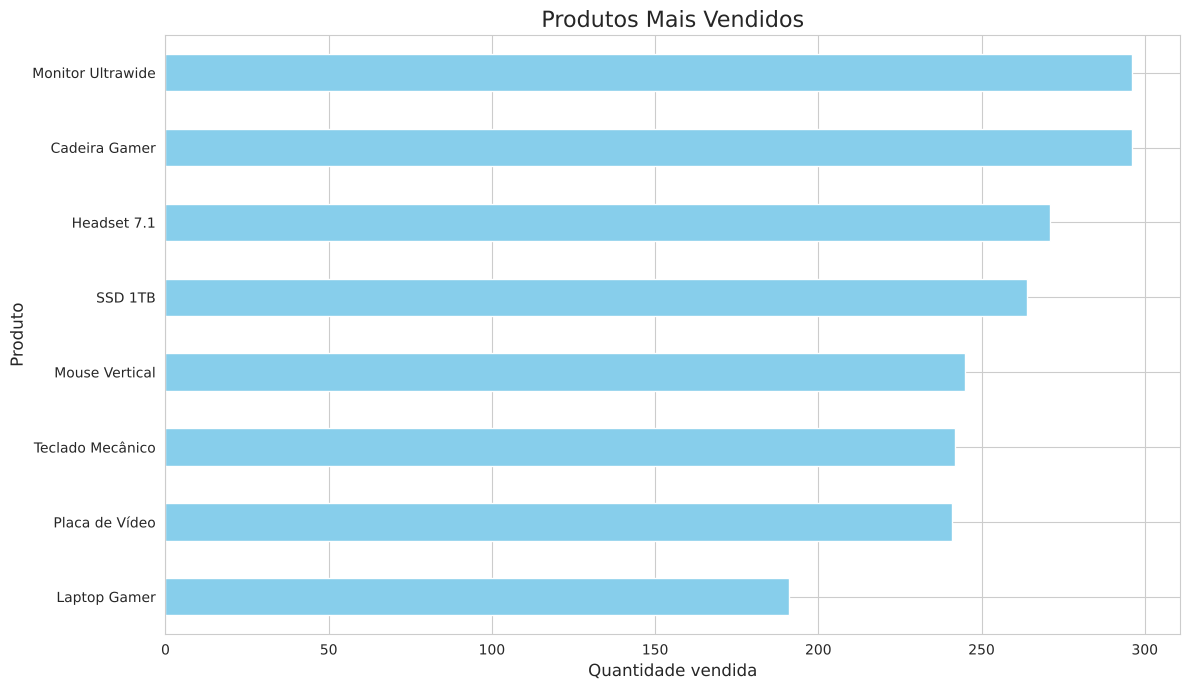

In [10]:
sns.set_style('whitegrid')

plt.figure(figsize=(12, 7))
top_produtos.sort_values(ascending=True).plot(kind='barh', color='skyblue')

plt.title('Produtos Mais Vendidos', fontsize=16)
plt.xlabel('Quantidade vendida', fontsize=12)
plt.ylabel('Produto', fontsize=12)

plt.tight_layout()
plt.savefig('imagens/01_produtos_mais_vendidos.png', dpi=100)
plt.show()

## Análise 2 - Faturamento Mensal

**Qual foi o faturamento mensal?**

In [11]:
# Agrupa por mês e soma o faturamento
faturamento_mensal = df_vendas.groupby('Mes')['Faturamento'].sum()

# Converte o índice para texto, para facilitar o gráfico
faturamento_mensal.index = faturamento_mensal.index.strftime('%Y-%m')

# Mostra formatado como moeda
faturamento_mensal.map('R$ {:,.2f}'.format)

Mes
2026-01    R$ 1,848,447.14
2026-02    R$ 1,798,725.26
2026-03    R$ 1,876,518.01
2026-04      R$ 602,326.31
Name: Faturamento, dtype: str

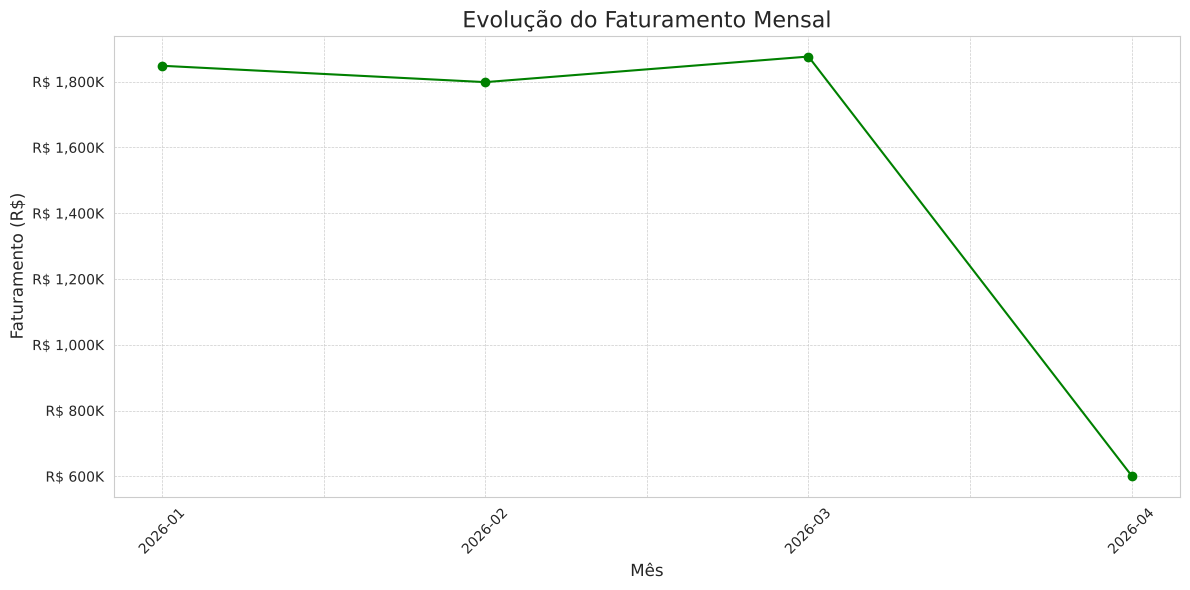

In [12]:
plt.figure(figsize=(12, 6))
faturamento_mensal.plot(kind='line', linestyle='-', marker='o', color='green')
plt.gca().yaxis.set_major_formatter(FuncFormatter(formatador_milhares))

plt.title('Evolução do Faturamento Mensal', fontsize=16)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.savefig('imagens/02_faturamento_mensal.png', dpi=100)
plt.show()

In [13]:
# Atenção: 500 pedidos a 5 por dia cobrem 100 dias (01/jan a 10/abr).
# Abril tem só 10 dias de dados, por isso a queda no gráfico não é uma queda real de vendas.
dias_por_mes = df_vendas.groupby('Mes')['Data_Pedido'].apply(lambda d: d.dt.date.nunique())
dias_por_mes

Mes
2026-01    31
2026-02    28
2026-03    31
2026-04    10
Freq: M, Name: Data_Pedido, dtype: int64

## Análise 3 - Vendas por Estado

**Qual o faturamento total por estado?**

In [14]:
vendas_estados = df_vendas.groupby('Estado')['Faturamento'].sum().sort_values(ascending=False)
vendas_estados.map('R$ {:,.2f}'.format)

Estado
CE    R$ 1,007,450.05
BA      R$ 966,172.77
RS      R$ 915,637.00
PR      R$ 894,151.31
MG      R$ 805,778.64
RJ      R$ 796,433.79
SP      R$ 740,393.16
Name: Faturamento, dtype: str

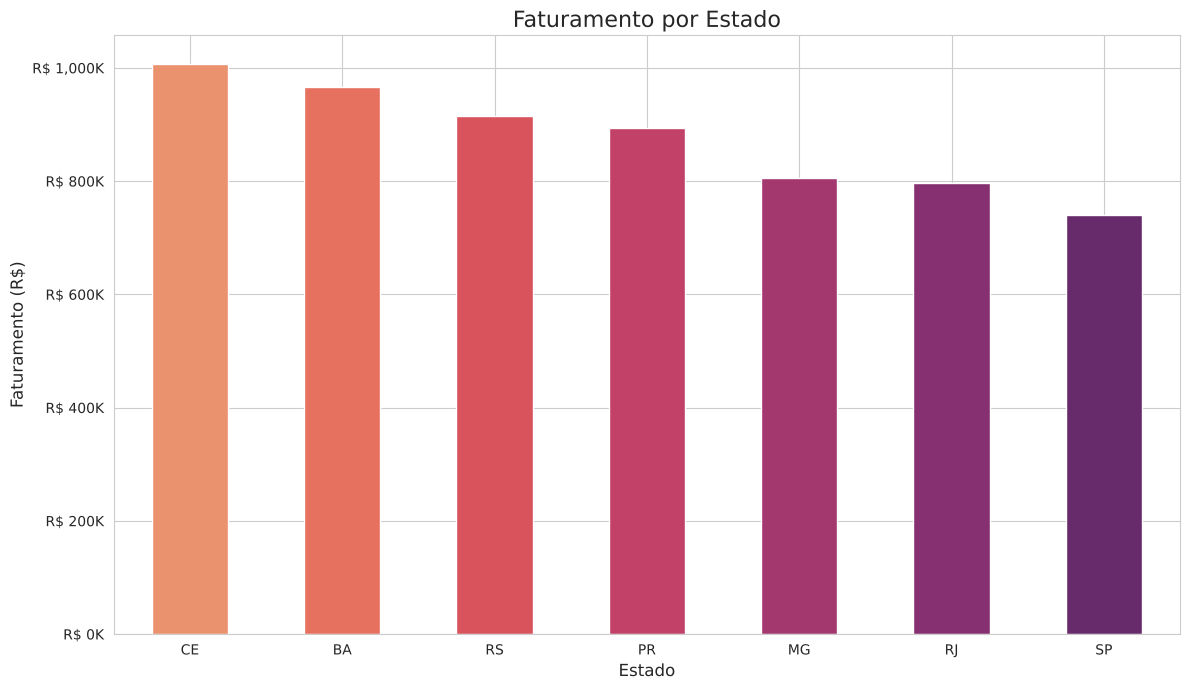

In [15]:
# Paleta "flare" do Seaborn: https://seaborn.pydata.org/generated/seaborn.color_palette.html
plt.figure(figsize=(12, 7))
vendas_estados.plot(kind='bar', color=sns.color_palette('flare', len(vendas_estados)))
plt.gca().yaxis.set_major_formatter(FuncFormatter(formatador_milhares))

plt.title('Faturamento por Estado', fontsize=16)
plt.xlabel('Estado', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('imagens/03_faturamento_por_estado.png', dpi=100)
plt.show()

## Análise 4 - Faturamento por Categoria

**Qual o faturamento total por categoria?**

In [16]:
faturamento_categoria = df_vendas.groupby('Categoria')['Faturamento'].sum().sort_values(ascending=False)
faturamento_categoria.map('R$ {:,.2f}'.format)

Categoria
Móveis         R$ 2,220,000.00
Eletrônicos    R$ 1,491,162.40
Hardware       R$ 1,242,900.00
Acessórios     R$ 1,171,954.32
Name: Faturamento, dtype: str

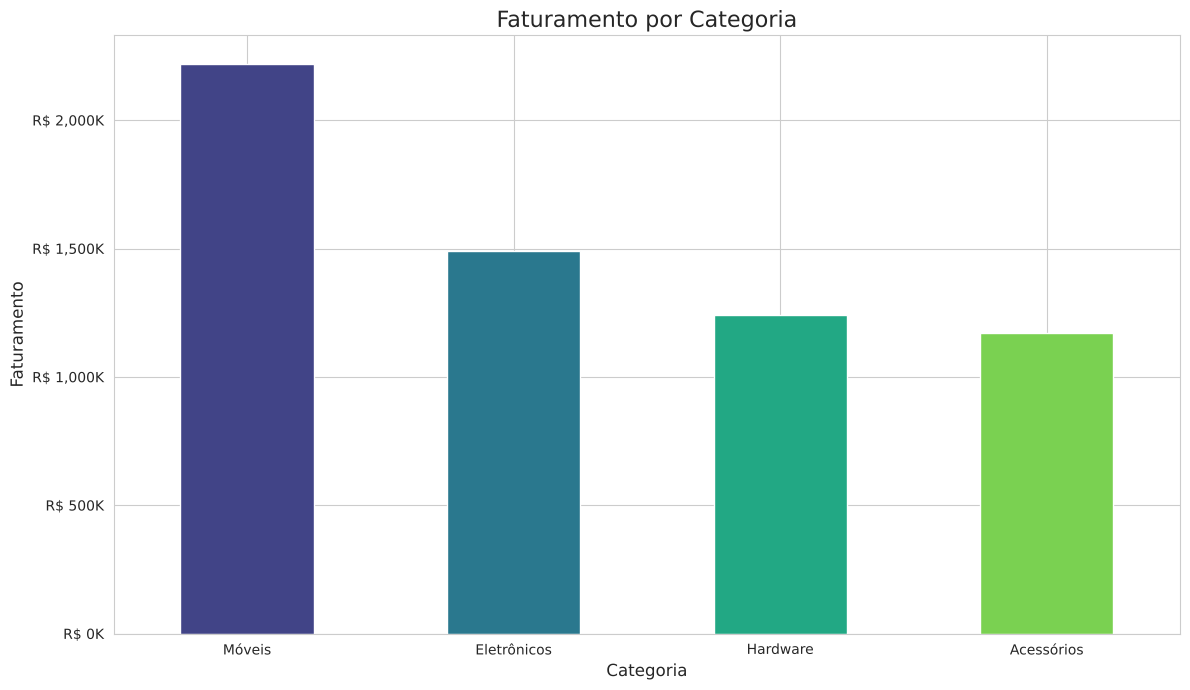

In [17]:
# formatador_milhares foi definido na célula de importações
# plt.subplots() dá mais controle sobre os elementos do gráfico
fig, ax = plt.subplots(figsize=(12, 7))
ax.yaxis.set_major_formatter(FuncFormatter(formatador_milhares))

faturamento_categoria.plot(kind='bar', ax=ax,
                           color=sns.color_palette('viridis', len(faturamento_categoria)))

ax.set_title('Faturamento por Categoria', fontsize=16)
ax.set_xlabel('Categoria', fontsize=12)
ax.set_ylabel('Faturamento', fontsize=12)
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('imagens/04_faturamento_por_categoria.png', dpi=100)
plt.show()

## Resumo dos Resultados

In [18]:
total = df_vendas['Faturamento'].sum()
print(f"Faturamento total:          R$ {total:,.2f}")
print(f"Pedidos analisados:         {len(df_vendas)}")
print(f"Ticket médio por pedido:    R$ {df_vendas['Faturamento'].mean():,.2f}")
print(f"Produto mais vendido (qtd): {top_produtos.index[0]} ({top_produtos.iloc[0]} unidades)")
print(f"Estado com maior faturamento: {vendas_estados.index[0]} (R$ {vendas_estados.iloc[0]:,.2f})")
print(f"Categoria líder:            {faturamento_categoria.index[0]} "
      f"({faturamento_categoria.iloc[0] / total:.0%} do faturamento)")

Faturamento total:          R$ 6,126,016.72
Pedidos analisados:         500
Ticket médio por pedido:    R$ 12,252.03
Produto mais vendido (qtd): Cadeira Gamer (296 unidades)
Estado com maior faturamento: CE (R$ 1,007,450.05)
Categoria líder:            Móveis (36% do faturamento)


## Conclusão e Entrega do Resultado

Existem várias formas de entregar um projeto de análise de dados. A escolha depende do público, do contexto e dos objetivos. Três formas bastante utilizadas:

- **Relatório técnico ou executivo** (PDF, DOCX etc.)
- **Dashboard interativo** (Power BI, Tableau, Looker, Streamlit, Dash etc.)
- **Apresentação** (slides em PowerPoint, Google Slides etc.)